# 02 · Map the BIODEP gene panel to microarray probes

**Aim:** find which probes on the Affymetrix U133 Plus 2.0 array measure the 16 genes of the BIODEP panel ([Cattaneo et al., 2020](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC7376244/)).

In [1]:
import warnings
from pathlib import Path

import GEOparse
import pandas as pd

raw_dir = Path("../data/raw")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=pd.errors.DtypeWarning)
    gse = GEOparse.get_GEO(geo="GSE98793", destdir=str(raw_dir), silent=True)

platform = gse.gpls["GPL570"].table
print(platform.shape)
platform.columns.tolist()

(54675, 16)


['ID',
 'GB_ACC',
 'SPOT_ID',
 'Species Scientific Name',
 'Annotation Date',
 'Sequence Type',
 'Sequence Source',
 'Target Description',
 'Representative Public ID',
 'Gene Title',
 'Gene Symbol',
 'ENTREZ_GENE_ID',
 'RefSeq Transcript ID',
 'Gene Ontology Biological Process',
 'Gene Ontology Cellular Component',
 'Gene Ontology Molecular Function']

## 1. The BIODEP gene panel
The 16 genes measured by qPCR in the BIODEP study, grouped by biological family. GR is listed under its official symbol, NR3C1. This list is fixed before looking at expression values.

In [2]:
panel = {
    "IL1B": "inflammation",
    "IL6": "inflammation",
    "TNF": "inflammation",
    "MIF": "inflammation",
    "CCL2": "inflammation",
    "CXCL12": "inflammation",
    "CRP": "inflammation",
    "A2M": "inflammation",
    "P2RX7": "inflammation",
    "NR3C1": "glucocorticoid",
    "FKBP5": "glucocorticoid",
    "SGK1": "glucocorticoid",
    "ISG15": "interferon",
    "STAT1": "interferon",
    "USP18": "interferon",
    "AQP4": "other",
}

len(panel)

16

In [3]:
matches = []

for probe_id, symbol_text in platform[["ID", "Gene Symbol"]].dropna().values:
    genes_on_probe = symbol_text.split(" /// ")
    for gene in genes_on_probe:
        if gene in panel:
            matches.append({
                "probe": probe_id,
                "gene": gene,
                "family": panel[gene],
                "n_genes_on_probe": len(genes_on_probe),
            })

probe_map = pd.DataFrame(matches)
probe_map["gene"].value_counts()

gene
STAT1     6
NR3C1     5
AQP4      5
FKBP5     3
A2M       2
CXCL12    2
IL1B      2
CRP       2
P2RX7     2
SGK1      1
IL6       1
ISG15     1
TNF       1
CCL2      1
MIF       1
USP18     1
Name: count, dtype: int64

In [4]:
probe_map["suffix"] = probe_map["probe"].str.extract(r"(_s_at|_x_at|_at)$")
probe_map.sort_values(["family", "gene"])

,probe,gene,family,n_genes_on_probe,suffix
6,204560_at,FKBP5,glucocorticoid,1,_at
25,224840_at,FKBP5,glucocorticoid,1,_at
26,224856_at,FKBP5,glucocorticoid,1,_at
3,201865_x_at,NR3C1,glucocorticoid,1,_x_at
4,201866_s_at,NR3C1,glucocorticoid,1,_s_at
19,211671_s_at,NR3C1,glucocorticoid,1,_s_at
20,216321_s_at,NR3C1,glucocorticoid,1,_s_at
29,232431_at,NR3C1,glucocorticoid,1,_at
2,201739_at,SGK1,glucocorticoid,1,_at
0,1558450_at,A2M,inflammation,1,_at


## 3. Expression data
Load the expression values (one row per probe, one column per sample) and check how they were processed.

In [5]:
pheno = gse.phenotype_data
print(pheno["data_processing"].unique())

expr = gse.pivot_samples("VALUE")
print(expr.shape)
expr.iloc[:, :5].describe().round(2)

<StringArray>
['The data were read and RMA-normalized using the Bioconductor package affy (default parameters).']
Length: 1, dtype: str
(54675, 192)


name,GSM2612096,GSM2612097,GSM2612098,GSM2612099,GSM2612100
count,54675.00,54675.00,54675.00,54675.00,54675.00
mean,5.44,5.42,5.39,5.38,5.43
std,2.31,2.36,2.45,2.40,2.34
min,1.43,1.38,1.34,1.41,1.50
25%,3.63,3.55,3.40,3.45,3.60
50%,5.04,4.94,4.93,4.89,5.00
75%,6.89,6.99,7.10,6.99,6.94
max,14.19,14.20,14.25,14.25,14.22


In [6]:
pheno = gse.phenotype_data
print(pheno["data_processing"].unique())

expr = gse.pivot_samples("VALUE")
print(expr.shape)
expr.iloc[:, :10].describe().round(2)

<StringArray>
['The data were read and RMA-normalized using the Bioconductor package affy (default parameters).']
Length: 1, dtype: str
(54675, 192)


name,GSM2612096,GSM2612097,GSM2612098,GSM2612099,GSM2612100,GSM2612101,GSM2612102,GSM2612103,GSM2612104,GSM2612105
count,54675.00,54675.00,54675.00,54675.00,54675.00,54675.00,54675.00,54675.00,54675.00,54675.00
mean,5.44,5.42,5.39,5.38,5.43,5.42,5.43,5.41,5.39,5.41
std,2.31,2.36,2.45,2.40,2.34,2.38,2.38,2.36,2.38,2.37
min,1.43,1.38,1.34,1.41,1.50,1.51,1.32,1.47,1.42,1.47
25%,3.63,3.55,3.40,3.45,3.60,3.52,3.52,3.54,3.49,3.51
50%,5.04,4.94,4.93,4.89,5.00,4.89,4.92,4.99,4.95,4.96
75%,6.89,6.99,7.10,6.99,6.94,7.04,7.04,6.96,6.97,6.97
max,14.19,14.20,14.25,14.25,14.22,14.14,14.11,14.29,14.28,14.27


## 4. Sample quality control

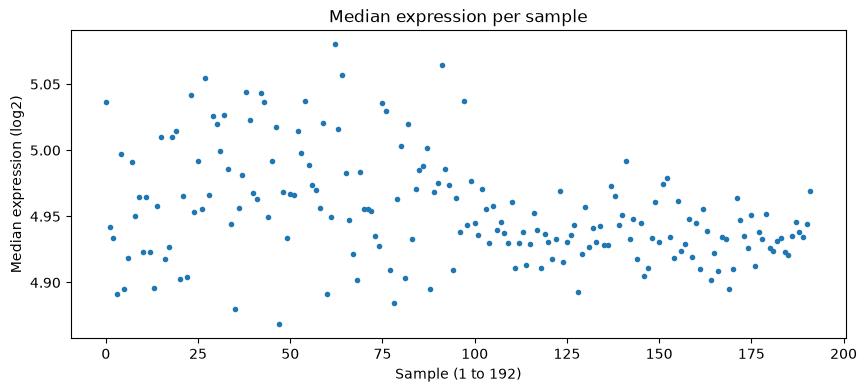

count    192.000
mean       4.954
std        0.040
min        4.868
25%        4.928
50%        4.945
75%        4.973
max        5.080
dtype: float64

In [7]:
import matplotlib.pyplot as plt

sample_medians = expr.median()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(sample_medians)), sample_medians.values, "o", markersize=3)
ax.set_xlabel("Sample (1 to 192)")
ax.set_ylabel("Median expression (log2)")
ax.set_title("Median expression per sample")
plt.show()

sample_medians.describe().round(3)

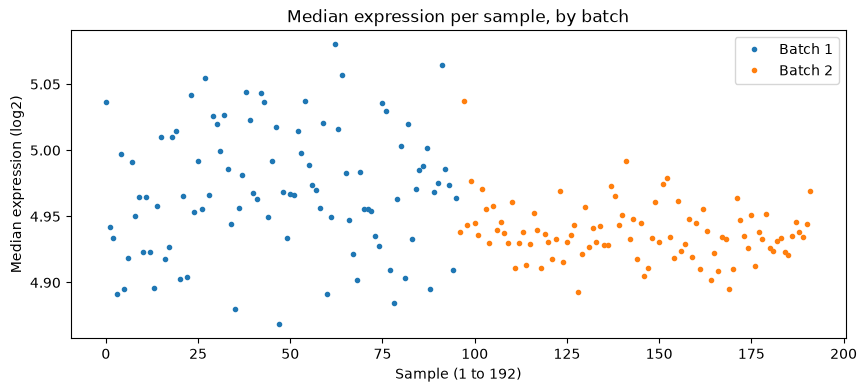

,count,mean,std,min,25%,50%,75%,max
batch,,,,,,,,
1,96.0,4.970,0.048,4.868,4.935,4.968,5.005,5.080
2,96.0,4.938,0.022,4.893,4.926,4.935,4.947,5.037


In [8]:
samples = pd.read_csv("../data/processed/GSE98793_samples.csv", index_col=0)
samples = samples.loc[expr.columns]
samples["median"] = sample_medians
samples["position"] = range(len(samples))

fig, ax = plt.subplots(figsize=(10, 4))
for batch_name, batch_samples in samples.groupby("batch"):
    ax.plot(batch_samples["position"], batch_samples["median"], "o", markersize=3, label=f"Batch {batch_name}")
ax.set_xlabel("Sample (1 to 192)")
ax.set_ylabel("Median expression (log2)")
ax.set_title("Median expression per sample, by batch")
ax.legend()
plt.show()

samples.groupby("batch")["median"].describe().round(3)

**Result.** All 192 sample medians lie between 4.87 and 5.08 (log2), so no sample is grossly abnormal. The two processing batches differ in spread: batch 1 (samples 1–96) has about twice the standard deviation of batch 2 (0.048 vs 0.022). Each batch contains 64 cases and 32 controls, so batch cannot create a false case–control difference, but it adds noise. Batch will be included as a covariate in the regression model, as in Leday et al. (2018).

## 5. Principal component analysis
PCA summarises the 54,675 probes into a few axes that capture the largest differences between samples. We use it to look for outlier samples and to see whether batch or diagnosis drives the main sources of variation.

Variance explained: [0.306 0.114 0.044 0.029 0.02 ]


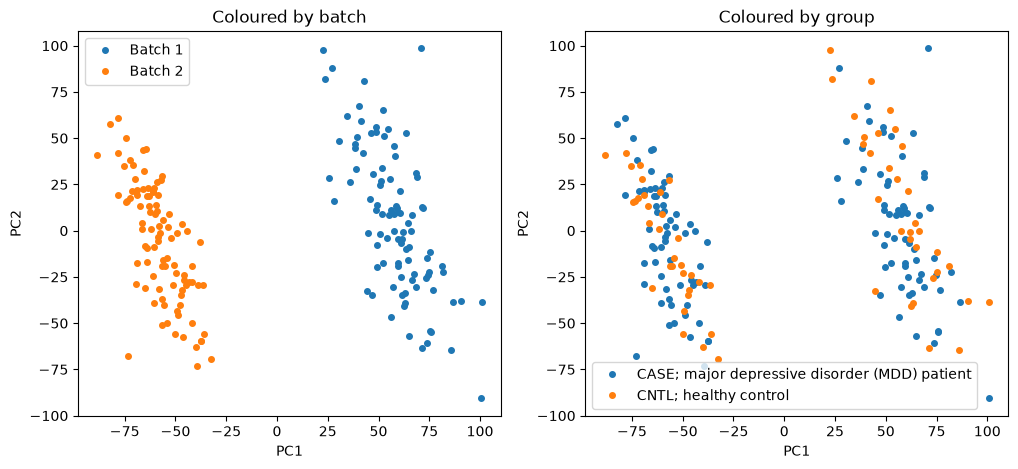

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=5)
coords = pca.fit_transform(expr.T.values)

samples["PC1"] = coords[:, 0]
samples["PC2"] = coords[:, 1]

print("Variance explained:", pca.explained_variance_ratio_.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for batch_name, batch_samples in samples.groupby("batch"):
    axes[0].plot(batch_samples["PC1"], batch_samples["PC2"], "o", markersize=4, label=f"Batch {batch_name}")
axes[0].set_title("Coloured by batch")

for group_name, group_samples in samples.groupby("group"):
    axes[1].plot(group_samples["PC1"], group_samples["PC2"], "o", markersize=4, label=group_name)
axes[1].set_title("Coloured by group")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

plt.show()

**Result.** PC1 explains 30.6% of the variance and separates the two processing batches completely, so batch is the largest source of variation in this dataset. This effect was nearly invisible in the sample medians, because batch shifts different probes in different directions. Cases and controls are mixed within both batches, consistent with the balanced design (64 cases and 32 controls per batch). No sample is clearly separated from its batch; one batch 1 sample (bottom right) is slightly isolated and is flagged for later review. Batch must be included in all models.

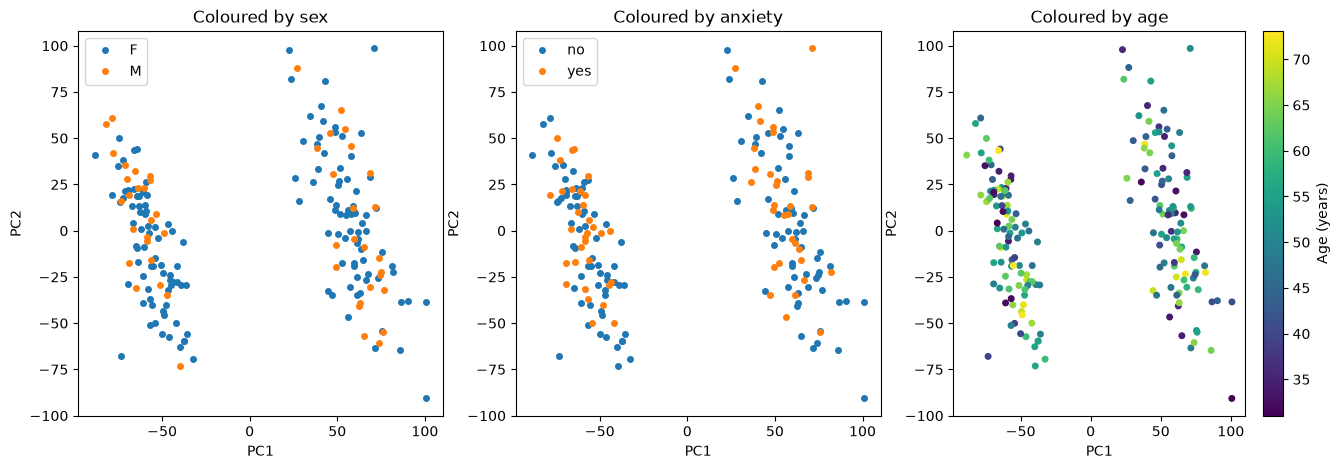

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for sex, sex_samples in samples.groupby("sex"):
    axes[0].plot(sex_samples["PC1"], sex_samples["PC2"], "o", markersize=4, label=sex)
axes[0].set_title("Coloured by sex")
axes[0].legend()

for anxiety, anxiety_samples in samples.groupby("anxiety"):
    axes[1].plot(anxiety_samples["PC1"], anxiety_samples["PC2"], "o", markersize=4, label=anxiety)
axes[1].set_title("Coloured by anxiety")
axes[1].legend()

points = axes[2].scatter(samples["PC1"], samples["PC2"], c=samples["age"], s=16, cmap="viridis")
fig.colorbar(points, ax=axes[2], label="Age (years)")
axes[2].set_title("Coloured by age")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.show()

In [11]:
symbols = platform.set_index("ID")["Gene Symbol"]

pc2 = pd.DataFrame({
    "gene": symbols.reindex(expr.index).values,
    "loading": pca.components_[1],
}, index=expr.index)

pc2 = pc2.sort_values("loading")

print("Lowest loadings (genes higher at the bottom of PC2):")
print(pc2.head(15))
print()
print("Highest loadings (genes higher at the top of PC2):")
print(pc2.tail(15))

Lowest loadings (genes higher at the bottom of PC2):
                                         gene   loading
ID_REF                                                 
219630_at                            PDZK1IP1 -0.015918
1553589_a_at                         PDZK1IP1 -0.015052
206655_s_at   GP1BB /// SEPT5 /// SEPT5-GP1BB -0.014373
223777_at                             DDX11L2 -0.014159
223717_s_at                             ACRBP -0.013900
210395_x_at                              MYL4 -0.013756
208792_s_at                               CLU -0.013670
208791_at                                 CLU -0.013578
231982_at                              SMIM24 -0.013475
210088_x_at                              MYL4 -0.013161
204081_at                                NRGN -0.012957
203370_s_at                            PDLIM7 -0.012935
230833_at                               ACRBP -0.012865
209728_at                            HLA-DRB4 -0.012839
216054_x_at                              MYL4 -0.01

**Result.** Sex, anxiety and age do not explain PC2 (11.4% of variance). Probes with the most negative PC2 loadings belong to genes known to be highly expressed in platelets (GP1BB, CLU, NRGN, PDZK1IP1, ACRBP, PDLIM7, SEPT5), suggesting that PC2 partly reflects platelet content in the blood samples. Genes at the positive end show no clear cell-type pattern. Cell composition will be considered as a possible confounder in later analyses.